# 04 — Exact attribution and the ownership decomposition

**Scope.** Read-only display of the shipped **V2 aggregate tables** in
`results/framework_pilot_v2/` plus the provisional stability tables. CPU only;
no model fitting, no ICEWS reads, no row-level predictions, no caches. Every
number below is an aggregate computed by the restricted runner and frozen with
`results/framework_pilot_v2/SHA256SUMS`; nothing is recomputed here.

**Evidential status.** V2 is a **post-hoc secondary** analysis on a burned
holdout. It cannot upgrade the V1 49-feature primary, and the ownership rule is
an analysis convention applied after the fact, not a plan-declared or
preregistered object.

**What the decomposition is.** The deployed model is a standardised L2 logistic,
`p = sigma(eta)` with `eta = b + sum_j w_j z_j` and
`z_j = (x_j - mu_j) / s_j`. The class sums are therefore exact:

- the additive identity is `b + sum_j c_ij = logit(p_i)` with
  `c_ij = w_j z_ij`;
- it is the logistic identity, equal to linear SHAP under a training-mean
  background, **not** a new estimator;
- the frozen check over 50,000 evaluation rows is `max |eps| = 1.15e-14`, i.e.
  floating-point exact.

The only thing this notebook adds is bookkeeping: which owner each feature is
assigned to, and what that convention does to the reported shares.


In [1]:
from pathlib import Path
import json

import pandas as pd

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

try:
    from IPython.display import display
except Exception:
    display = print


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in (here, *here.parents):
        if (cand / "results" / "framework_pilot").is_dir():
            return cand
    return here


ROOT = find_repo_root()
V2 = ROOT / "results" / "framework_pilot_v2"
V2T = V2 / "tables"
V2P = V2 / "parts"
V1_STAB = ROOT / "results" / "framework_pilot" / "stability" / "tables"


def rel(path: Path) -> str:
    try:
        return str(Path(path).relative_to(ROOT))
    except ValueError:
        return str(path)


def load_csv(path: Path) -> pd.DataFrame:
    if not path.is_file():
        print(f"[missing] {rel(path)}")
        return pd.DataFrame()
    return pd.read_csv(path)


def load_json(path: Path) -> dict:
    if not path.is_file():
        print(f"[missing] {rel(path)}")
        return {}
    with path.open(encoding="utf-8") as fh:
        return json.load(fh)


MORANDI = {
    "slate": "#35525F",
    "terracotta": "#A2664F",
    "sage": "#84957A",
    "ochre": "#C2A05F",
    "brick": "#8C5A52",
    "ink": "#33383B",
    "grey": "#8B8883",
    "sand": "#E6DED2",
}

def show_figure(fig) -> None:
    # Render as an embedded PNG: the executor runs without an inline backend.
    try:
        import io
        from IPython.display import Image, display as show
        buffer = io.BytesIO()
        fig.savefig(buffer, format="png", dpi=150, bbox_inches="tight")
        show(Image(data=buffer.getvalue()))
    except Exception as exc:
        print(f"[figure not rendered] {exc}")


CLASSES = ["source_actor", "target_actor", "dyad", "calendar", "graph",
           "train_stats"]
LABELS = {
    "source_actor": "source actor",
    "target_actor": "target actor",
    "dyad": "dyad (pair history)",
    "calendar": "calendar",
    "graph": "symmetric graph",
    "train_stats": "train-only statistics",
    "actor_dyad_interaction": "actor-dyad interaction",
}

print("repo root:", rel(ROOT))
print("V2 aggregate tree:", "present" if V2.is_dir() else "MISSING")
print("tables shipped:", len(sorted(V2T.glob("*.csv"))) if V2T.is_dir() else 0)


repo root: .
V2 aggregate tree: present
tables shipped: 16


## 1. Six ownership classes

One owner per feature, fixed by the convention: `src_*`/`g_*_s`/`nra_s` to the
source actor, the same suffix `_t` to the target, pair-history columns to the
dyad, month columns to the calendar, the five undirected graph terms plus the
two ego counts to the graph class, and `br`/`seen_tr` to train-only statistics.

The table is the frozen `a8_ownership.csv`. `F2@inn` is the 49-feature fit on the
inner window (252–274) and is the V2 recomputation of the V1 shares; `F2@ev` and
`F3@ev` are the burned 2018–22 evaluation window, shown for contrast.


In [2]:
own = load_csv(V2T / "a8_ownership.csv")

if not own.empty:
    body = own[own["class"] != "TOTAL"]
    shares = body.pivot(index="class", columns="period", values="share_pct")
    shares = shares.reindex([c for c in CLASSES if c in shares.index])
    shares.loc["actor-owned (source+target)"] = (
        shares.loc["source_actor"] + shares.loc["target_actor"])
    shares.loc["not actor-owned"] = (
        shares.loc["dyad"] + shares.loc["calendar"] + shares.loc["graph"]
        + shares.loc["train_stats"])
    display(shares.round(2))
    print("six classes plus two derived totals; the six classes sum to 100% "
          "in every column")
    print("periods: F2@ev / F2@inn / F3@ev = burned eval (49), inner (49), "
          "burned eval (47)")
else:
    shares = pd.DataFrame()
    print("No ownership table; later cells will report missing inputs.")


period,F2@ev,F2@inn,F3@ev
class,,,
source_actor,22.56,21.69,16.67
target_actor,24.51,23.52,18.15
dyad,29.87,29.05,32.19
calendar,4.13,3.23,2.48
graph,18.93,18.17,30.51
train_stats,0.00,4.35,0.00
actor-owned (source+target),47.07,45.21,34.82
not actor-owned,52.93,54.79,65.18


six classes plus two derived totals; the six classes sum to 100% in every column
periods: F2@ev / F2@inn / F3@ev = burned eval (49), inner (49), burned eval (47)


## 2. Why the headline is 55.1 / 62.3 and what V2 recomputes

Two different questions produce two different "not actor-owned" numbers:

- **55.1%** — the six-class view: everything that is not a source- or
  target-actor feature. The V1 6.34 M-row fit reported **55.07%**; the V2
  5.06 M-row fit reports **54.79%**.
- **62.3%** — the seven-class view: `g_nra_s`/`g_nra_t` are neighbour-activity
  aggregates that depend on the *partner*, so a stricter convention moves them
  out of the actor class into an "actor-dyad interaction" class. V1 reported
  **62.27%**; V2 reports **63.17%**.

Both shifts are a single percentage point or less, and both come from a
different training window (5.06 M vs 6.34 M rows), not from a re-fit of V1.


In [3]:
a8 = load_json(V2P / "a8_ownership.json")

if a8:
    seven = a8["g_nra_reclassification_F2inn"]
    block = pd.DataFrame(
        [(LABELS[k], round(float(v), 2)) for k, v in seven["shares_pct"].items()],
        columns=["class (seven-class view)", "share_pct"],
    )
    display(block)

    v2_six = float(shares.loc["not actor-owned", "F2@inn"]) if not shares.empty else float("nan")
    v1_six = float(a8["v1_targets"]["not_actor_pct"])
    v2_seven = float(seven["not_actor_pct"])
    v1_seven = float(seven["v1_not_actor_target"])
    pairs = pd.DataFrame(
        [("six-class", v1_six, v2_six, v2_six - v1_six),
         ("seven-class (g_nra moved out)", v1_seven, v2_seven, v2_seven - v1_seven)],
        columns=["convention", "V1 6.34M-row fit (%)", "V2 5.06M-row fit (%)",
                 "delta (pp)"],
    )
    display(pairs.round(2))
    print(f"headline pair: {v1_six:.1f} / {v1_seven:.1f} (V1) -> "
          f"{v2_six:.1f} / {v2_seven:.1f} (V2)")
    print("train rows:", a8["train_rows_v1"], "->", a8["train_rows_v2"],
          f"({a8['train_row_delta']:+,})")
else:
    pairs = pd.DataFrame()
    print("No ownership JSON; the headline pair cannot be displayed.")


,class (seven-class view),share_pct
0,source actor,17.48
1,target actor,19.35
2,dyad (pair history),29.05
3,calendar,3.23
4,symmetric graph,18.17
5,train-only statistics,4.35
6,actor-dyad interaction,8.38


,convention,V1 6.34M-row fit (%),V2 5.06M-row fit (%),delta (pp)
0,six-class,55.07,54.79,-0.28
1,seven-class (g_nra moved out),62.27,63.17,0.90


headline pair: 55.1 / 62.3 (V1) -> 54.8 / 63.2 (V2)
train rows: 6344160 -> 5055328 (-1,288,832)


## 3. Six classes against the V1 targets

The bars compare the V2 recomputation with the V1 shares that the manuscript
quotes. The convention is identical in both; only the training window and the
fit differ.


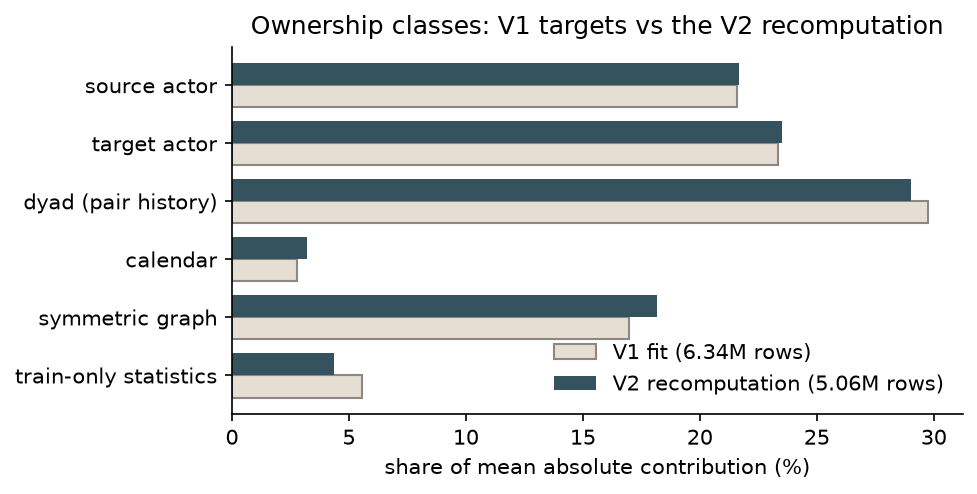

In [4]:
if not pairs.empty and not shares.empty:
    import matplotlib.pyplot as plt

    plot_classes = CLASSES
    v1 = [float(a8["v1_targets"]["shares_pct"][c]) for c in plot_classes]
    v2 = [float(shares.loc[c, "F2@inn"]) for c in plot_classes]

    fig, ax = plt.subplots(figsize=(6.6, 3.4))
    y = range(len(plot_classes))
    height = 0.38
    ax.barh([i + height / 2 for i in y], v1, height=height,
            color=MORANDI["sand"], edgecolor=MORANDI["grey"],
            label="V1 fit (6.34M rows)")
    ax.barh([i - height / 2 for i in y], v2, height=height,
            color=MORANDI["slate"], label="V2 recomputation (5.06M rows)")
    ax.set_yticks(list(y))
    ax.set_yticklabels([LABELS[c] for c in plot_classes])
    ax.invert_yaxis()
    ax.set_xlabel("share of mean absolute contribution (%)")
    ax.set_title("Ownership classes: V1 targets vs the V2 recomputation")
    ax.legend(frameon=False, loc="lower right")
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    fig.tight_layout()
    show_figure(fig)
else:
    print("Figure skipped: ownership table or JSON unavailable.")


## 4. The decomposition is exact, and almost nothing is role-specific

The exactness block is the frozen diagnostic on 50,000 sampled evaluation rows:
`b + sum_j c_ij` reproduces `logit(p_i)` to 1.15e-14, far inside the 1e-5
tolerance. The role counts answer a different question: **how many of the 49
features are genuinely specific to the source or the target actor?**

- 14 of 49 columns are actor-owned (`SOURCE_OWN` + `TARGET_OWN`).
- 5 of the 7 source/target column pairs are the *same* undirected graph term
  (`deg`, `wdeg`, `deg12`, `eig`, `pr`), so the pair is duplicated across roles.
- Only 4 columns are role-unique: `g_nra_s`, `g_nra_t`, `src_ev`, `tgt_ev`.
- 12 of the 14 actor-owned columns are partner-blind at fixed (actor, month);
  only the two `g_nra_*` terms vary across partners.


In [5]:
if a8:
    ex = a8["exactness"]
    roles = a8["role_counts"]
    rb = roles["n_role_unique"]
    rows = [
        ("rows checked", f"{int(ex['n_rows']):,} (sampled evaluation rows)"),
        ("max |eps| (logit round-trip)", f"{ex['raw_max_abs_error']:.3e}"),
        ("mean |eps|", f"{ex['raw_mean_abs_error']:.3e}"),
        ("rows above 1e-5", int(ex["rows_above_tol"])),
        ("exactness pass", bool(ex["pass"])),
        ("actor-owned columns", f"{roles['n_actor_owned']['value']} of "
                                f"{roles['n_actor_owned']['of']}"),
        ("duplicated graph pairs", roles["n_duplicate_graph_pairs"]["value"]),
        ("role-unique columns", f"{rb['value']} of {rb['of']}: "
                               + ", ".join(rb["features"])),
        ("partner-blind actor columns",
         f"{roles['n_partner_blind']['value']} of "
         f"{roles['n_partner_blind']['of']}"),
    ]
    display(pd.DataFrame(rows, columns=["check", "frozen value"]))
    print("reading: the additive identity is a property of the estimator; the "
          "role split is a property of the feature contract")
else:
    print("No ownership JSON; exactness block unavailable.")


,check,frozen value
0,rows checked,"50,000 (sampled evaluation rows)"
1,max |eps| (logit round-trip),1.155e-14
2,mean |eps|,7.027e-17
3,rows above 1e-5,0
4,exactness pass,True
5,actor-owned columns,14 of 49
6,duplicated graph pairs,5
7,role-unique columns,"4 of 49: g_nra_s, g_nra_t, src_ev, tgt_ev"
8,partner-blind actor columns,12 of 14


reading: the additive identity is a property of the estimator; the role split is a property of the feature contract


## 5. Near-collinearity of the source/target blocks

`a8_structural.csv` holds three structural checks computed on the frozen
feature panels: partner blindness (does an "actor" column change when only the
partner changes?), reversal invariance (`f_s(i, j) == f_t(j, i)`), and the
absolute asymmetry of the neighbour-activity term.

This is why the source/target shares are bookkeeping, not two independent
signals: with five duplicated undirected terms, a large part of the
source/target split is decided by the convention, not by the data.


In [6]:
struct = load_csv(V2T / "a8_structural.csv")

if not struct.empty:
    blind = struct[struct["check"] == "partner_blindness"].copy()
    blind["varies across partners"] = blind["cells_gt1"].astype(int) > 0
    display(blind[["feature", "cells", "cells_gt1", "max_distinct",
                   "total_distinct_values", "varies across partners"]]
            .reset_index(drop=True))

    rev = struct[struct["check"] == "reversal_invariance"].copy()
    sym = struct[struct["check"] == "g_nra_symmetry"].copy()
    print("reversal invariance (role swap `_s(i,j) == _t(j,i)`):")
    for _, row in rev.iterrows():
        fields = {name: row[name] for name in ("cells", "matched", "pass", "rate")
                  if name in rev.columns and pd.notna(row[name])}
        shown = ", ".join(f"{k}={v:g}" for k, v in fields.items())
        print(f"  {row['feature']:>20s}  {shown}")
    if not sym.empty:
        print("mean |g_nra_s - g_nra_t| on the panel:",
              f"{float(sym['mean_abs'].iloc[0]):.4f}")
    print("partner-blind columns are constant for a given actor-month; only "
          "the two g_nra terms vary with the partner")
else:
    print("No structural table; near-collinearity checks unavailable.")


,feature,cells,cells_gt1,max_distinct,total_distinct_values,varies across partners
0,src_ev,195.0,0.0,1.0,132.0,False
1,g_deg_s,195.0,0.0,1.0,114.0,False
2,g_wdeg_s,195.0,0.0,1.0,195.0,False
3,g_deg12_s,195.0,0.0,1.0,105.0,False
4,g_eig_s,195.0,0.0,1.0,196.0,False
5,g_pr_s,195.0,0.0,1.0,196.0,False
6,g_nra_s,195.0,195.0,137.0,1027.0,True


reversal invariance (role swap `_s(i,j) == _t(j,i)`):
       g_deg_s=g_deg_t  matched=3798, pass=3798, rate=1
     g_wdeg_s=g_wdeg_t  matched=3798, pass=3798, rate=1
   g_deg12_s=g_deg12_t  matched=3798, pass=3798, rate=1
       g_eig_s=g_eig_t  matched=3798, pass=3798, rate=1
         g_pr_s=g_pr_t  matched=3798, pass=3798, rate=1
       g_nra_s=g_nra_t  matched=3798, pass=3798, rate=1
         src_ev=tgt_ev  matched=3798, pass=3798, rate=1
mean |g_nra_s - g_nra_t| on the panel: 0.9659
partner-blind columns are constant for a given actor-month; only the two g_nra terms vary with the partner


## 6. The allocation range: the honest error bar on "not actor-owned"

Because ownership of the symmetric graph class is a judgement call, V2 reports
a range instead of one number: graph counted as unowned (a), as actor-owned (b),
or split in half (c). The V1 triple sits inside the same range, and the span
equals the whole graph class (18.2 percentage points in V2).


In [7]:
alloc = load_csv(V2T / "a8_allocations.csv")

if not alloc.empty and a8:
    conv = {"a_graph_unowned": "a — graph unowned (headline)",
            "b_graph_all_actor": "b — graph counted as actor",
            "c_graph_half": "c — graph split in half"}
    v2rows = [(conv.get(r.convention, r.convention), float(r.not_actor_pct))
              for r in alloc.itertuples() if not r.convention.startswith("v1_")]
    v1rows = [(f"V1 convention {int(r.convention.split('_')[1]) + 1}",
               float(r.not_actor_pct))
              for r in alloc.itertuples() if r.convention.startswith("v1_")]
    display(pd.DataFrame(v1rows + v2rows,
                         columns=["convention", "not actor-owned (%)"]).round(2))
    span = float(a8["allocation_range_F2inn"]["span_pct"])
    v2_vals = [v for _, v in v2rows]
    print(f"V2 range {min(v2_vals):.2f}-{max(v2_vals):.2f}%, span {span:.2f} pp "
          f"= the graph class ({float(shares.loc['graph', 'F2@inn']):.2f}%)")
    print("the V1 triple 55.07 / 38.11 / 46.59 lies inside the V2 range")
else:
    print("No allocation table; the range cannot be displayed.")


,convention,not actor-owned (%)
0,V1 convention 1,55.07
1,V1 convention 2,38.11
2,V1 convention 3,46.59
3,a — graph unowned (headline),54.79
4,b — graph counted as actor,36.63
5,c — graph split in half,45.71


V2 range 36.63-54.79%, span 18.17 pp = the graph class (18.17%)
the V1 triple 55.07 / 38.11 / 46.59 lies inside the V2 range


## 7. Do the actor attributions survive refitting? (V2 A9, provisional)

A9 refits the same 47-feature specification on 50 dyad-cluster bootstrap
replicates and compares the resulting actor attribution vectors pairwise
(Spearman) and by top-k membership (Jaccard). `P1` is the as-specified graph
cache; `H0` is the holdout-zeroed cache. Both are **provisional**: 50 refits,
post-hoc, and never a confirmatory statement.


In [8]:
stab = load_csv(V2T / "a9_stability.csv")
cross = load_csv(V2T / "a9_crosscache.csv")

if not stab.empty:
    keep = {"spearman_median": "Spearman median",
            "jaccard@10_median": "top-10 Jaccard median",
            "jaccard@50_median": "top-50 Jaccard median",
            "replicate_sd_median": "replicate SD (median)"}
    rows = []
    for cache in ("P1", "H0"):
        for role in ("source", "target"):
            sel = stab[(stab["cache"] == cache) & (stab["role"] == role)]
            for metric, label in keep.items():
                value = sel[sel["metric"] == metric]["value"]
                rows.append((cache, role, label,
                             float(value.iloc[0]) if len(value) else float("nan")))
    table = pd.DataFrame(rows, columns=["cache", "role", "metric", "value"])
    display(table.pivot_table(index=["role", "metric"], columns="cache",
                              values="value").round(3))

if not cross.empty:
    display(cross.assign(value=cross["value"].astype(float).round(4))
            .rename(columns={"metric": "cross-cache metric"}))
    print("cross-cache reading: rank agreement stays high (Spearman ~0.93) "
          "while top-10 membership overlaps only ~0.54 — rank is stable, the "
          "exact alert list is not")


cache                            H0     P1
role   metric                             
source Spearman median        0.995  0.999
       replicate SD (median)  0.033  0.027
       top-10 Jaccard median  0.818  0.818
       top-50 Jaccard median  0.887  0.923
target Spearman median        0.996  0.999
       replicate SD (median)  0.033  0.029
       top-10 Jaccard median  0.818  0.818
       top-50 Jaccard median  0.961  0.887

,cross-cache metric,value,schema
0,spearman_source,0.9335,v2/a9_crosscache/1
1,spearman_target,0.9315,v2/a9_crosscache/1
2,jaccard10_source,0.5385,v2/a9_crosscache/1
3,jaccard10_target,0.5385,v2/a9_crosscache/1
4,coef_sign_flips,2.0000,v2/a9_crosscache/1
5,n_coef,47.0000,v2/a9_crosscache/1
6,delta_not_actor_share,-1.1812,v2/a9_crosscache/1


cross-cache reading: rank agreement stays high (Spearman ~0.93) while top-10 membership overlaps only ~0.54 — rank is stable, the exact alert list is not


## 8. Top-k churn and decision lift (V1 provisional audit)

The V2 stability pass reports rank/top-k agreement but no decision proxy; the
decision proxy is in the **V1 provisional audit**
(`stability/tables/decision_impact_dyad.csv`), which is a separate 50-refit,
holdout-excluded run. It answers: if an analyst reviews the `k` highest
attribution dyads in a period, what share of the actual positives is captured,
and how much better is that than the base rate?

`alert = risk` ranks by predicted risk (the ceiling), `total` by total absolute
attribution, and `source` / `target` by the role-specific vector alone.


,alert,k,precision,recall,lift_vs_base,jaccard_with_risk
0,risk,10,1.0000,0.0043,9.0528,1.0000
1,risk,100,0.9996,0.0428,9.0488,1.0000
2,risk,1000,0.8217,0.3517,7.4386,1.0000
3,total,10,1.0000,0.0043,9.0528,0.6667
4,total,100,0.9996,0.0428,9.0488,0.9608
5,total,1000,0.8221,0.3519,7.4426,0.9940
6,source,10,0.0130,0.0001,0.1181,0.0000
7,source,100,0.0209,0.0009,0.1889,0.0000
8,source,1000,0.0547,0.0234,0.4951,0.0055
9,target,10,0.0044,0.0000,0.0394,0.0000


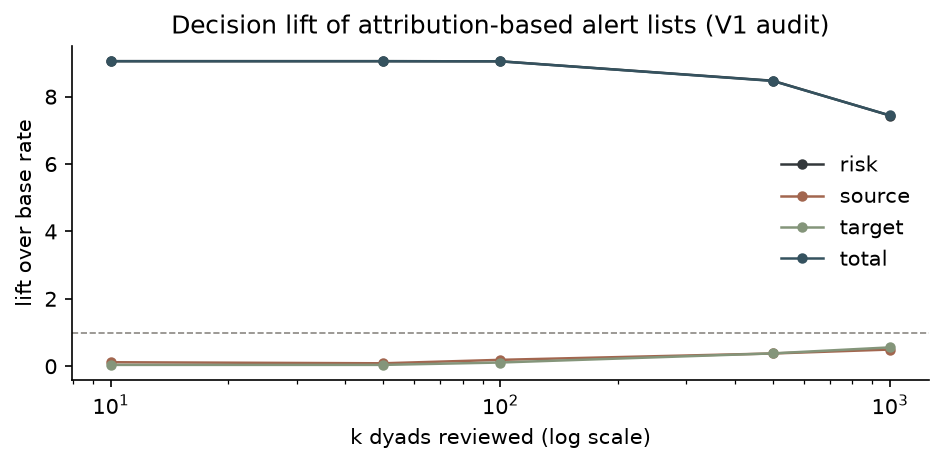

risk-ranked lift: 9.05 at k=10, 7.44 at k=1000
source-only lift at k=10: 0.12 — a role-specific list alone is not an alert signal


In [9]:
dec = load_csv(V1_STAB / "decision_impact_dyad.csv")

if not dec.empty:
    pick = dec[dec["k"].isin([10, 100, 1000])]
    display(pick[["alert", "k", "precision", "recall", "lift_vs_base",
                  "jaccard_with_risk"]].round(4).reset_index(drop=True))

    import matplotlib.pyplot as plt

    colours = {"risk": MORANDI["ink"], "total": MORANDI["slate"],
               "source": MORANDI["terracotta"], "target": MORANDI["sage"]}
    fig, ax = plt.subplots(figsize=(6.4, 3.2))
    for alert, block in dec.groupby("alert"):
        block = block.sort_values("k")
        ax.plot(block["k"], block["lift_vs_base"], marker="o", markersize=4,
                linewidth=1.2, color=colours.get(alert, MORANDI["grey"]),
                label=alert)
    ax.axhline(1.0, color=MORANDI["grey"], linewidth=0.8, linestyle="--")
    ax.set_xscale("log")
    ax.set_xlabel("k dyads reviewed (log scale)")
    ax.set_ylabel("lift over base rate")
    ax.set_title("Decision lift of attribution-based alert lists (V1 audit)")
    ax.legend(frameon=False)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    fig.tight_layout()
    show_figure(fig)

    head = dec[(dec["k"] == 10) & (dec["alert"] == "risk")].iloc[0]
    tail = dec[(dec["k"] == 1000) & (dec["alert"] == "risk")].iloc[0]
    src = dec[(dec["k"] == 10) & (dec["alert"] == "source")].iloc[0]
    print(f"risk-ranked lift: {float(head['lift_vs_base']):.2f} at k=10, "
          f"{float(tail['lift_vs_base']):.2f} at k=1000")
    print(f"source-only lift at k=10: {float(src['lift_vs_base']):.2f} — a "
          "role-specific list alone is not an alert signal")
else:
    print("No decision table; the lift panel is unavailable.")


## 9. What this notebook does **not** show

- No row-level contribution vector, no dyad identifier, no actor probability or
  observed rate. The removed `dyad_contributions_*` sample stays removed; see
  `DATA_EXCLUSIONS.md` §1 and §6.
- No re-fit, no bootstrap, no new test. A9 is provisional and post-hoc; it
  cannot promote or refute the V1 primary.
- No claim that the ownership shares are properties of the actors. They are
  descriptive outputs of a convention over a fixed feature list.
- No paper figure is regenerated here: `paper/` is not redistributed and the
  manuscript is cited by its arXiv link only.


In [10]:
summary_rows = []
if a8:
    summary_rows.append(("exactness max |eps|", f"{a8['exactness']['raw_max_abs_error']:.2e}"))
    summary_rows.append(("not actor-owned, six-class (V2)",
                         f"{float(shares.loc['not actor-owned', 'F2@inn']):.2f}%"))
    summary_rows.append(("not actor-owned, seven-class (V2)",
                         f"{float(a8['g_nra_reclassification_F2inn']['not_actor_pct']):.2f}%"))
    summary_rows.append(("role-unique columns",
                         f"{a8['role_counts']['n_role_unique']['value']} of 49"))
if not cross.empty:
    summary_rows.append(("cross-cache Spearman (source)",
                         f"{float(cross.loc[cross['metric'] == 'spearman_source', 'value'].iloc[0]):.3f}"))
display(pd.DataFrame(summary_rows, columns=["displayed aggregate", "value"]))
print("status: aggregates only; V2 post-hoc secondary; A9 provisional")


,displayed aggregate,value
0,exactness max |eps|,1.15e-14
1,"not actor-owned, six-class (V2)",54.79%
2,"not actor-owned, seven-class (V2)",63.17%
3,role-unique columns,4 of 49
4,cross-cache Spearman (source),0.934


status: aggregates only; V2 post-hoc secondary; A9 provisional
